Premiere exploration des données de Asthme -passage aux urgances

In [1]:
#import des librairies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [2]:
#pour construire le chemin d'accès aux fichiers de données

from pathlib import Path

raw = Path(r"C:\Users\monik\Documents\3_PRO\3_LEARNING\13_Formation_DATA_SCIENTIST\Projet\Fil_rouge\GitHub\LIORA_PROJET_PATHO_RESPIRATOIRES\notebooks")

print(list(raw.iterdir()))

[WindowsPath('C:/Users/monik/Documents/3_PRO/3_LEARNING/13_Formation_DATA_SCIENTIST/Projet/Fil_rouge/GitHub/LIORA_PROJET_PATHO_RESPIRATOIRES/notebooks/01a.Exploration_asthme_MLU.ipynb'), WindowsPath('C:/Users/monik/Documents/3_PRO/3_LEARNING/13_Formation_DATA_SCIENTIST/Projet/Fil_rouge/GitHub/LIORA_PROJET_PATHO_RESPIRATOIRES/notebooks/01b.Exploration_visuelle_asthme_MLU2.ipynb'), WindowsPath('C:/Users/monik/Documents/3_PRO/3_LEARNING/13_Formation_DATA_SCIENTIST/Projet/Fil_rouge/GitHub/LIORA_PROJET_PATHO_RESPIRATOIRES/notebooks/02a.Exploration_allergie_MLU .ipynb'), WindowsPath('C:/Users/monik/Documents/3_PRO/3_LEARNING/13_Formation_DATA_SCIENTIST/Projet/Fil_rouge/GitHub/LIORA_PROJET_PATHO_RESPIRATOIRES/notebooks/02b.Exploration_visuelle_allergie_MLU.ipynb'), WindowsPath('C:/Users/monik/Documents/3_PRO/3_LEARNING/13_Formation_DATA_SCIENTIST/Projet/Fil_rouge/GitHub/LIORA_PROJET_PATHO_RESPIRATOIRES/notebooks/03a.Exploration_bronchiolite_MLU.ipynb'), WindowsPath('C:/Users/monik/Documents/3

In [3]:
#pour construire le chemin d'accès aux fichiers de données

from pathlib import Path

raw = Path("../data/raw")

# Afficher tous les fichiers CSV, y compris dans les sous-dossiers
for fichier in raw.rglob("*.csv"):
    print(fichier)

..\data\raw\allergie-passages-aux-urgences-et-actes-sos-medecins-dep.csv
..\data\raw\asthme-passages-aux-urgences-et-actes-sos-medecins-dep.csv
..\data\raw\bronchiolite-passages-aux-urgences-et-actes-sos-medecins-departement.csv
..\data\raw\pollut_20261012084158 - 2025-01-01 00_00 - 2025-12-31 23_00.csv
..\data\raw\pollut_20261012084855 - 2025-01-01 00_00 - 2025-12-31 23_00.csv
..\data\raw\pollut_20261012084932 - 2025-01-01 00_00 - 2025-12-31 23_00.csv
..\data\raw\pollut_20261012085004 - 2025-01-01 00_00 - 2025-12-31 23_00.csv
..\data\raw\pollut_20261012085038 - 2025-01-01 00_00 - 2025-12-31 23_00.csv
..\data\raw\Sante\allergie-passages-aux-urgences-et-actes-sos-medecins-dep.csv
..\data\raw\Sante\asthme-passages-aux-urgences-et-actes-sos-medecins-dep.csv
..\data\raw\Sante\bronchiolite-passages-aux-urgences-et-actes-sos-medecins-departement.csv
..\data\raw\Sante\effectifs.csv


In [4]:
df_asthme = pd.read_csv(
    "../data/raw/Sante/asthme-passages-aux-urgences-et-actes-sos-medecins-dep.csv"
)
df_asthme.head()

,Semaine,1er jour de la semaine,Département,Région,Classe d'âge,Taux de passages aux urgences pour asthme,Taux d'hospitalisations après passages aux urgences pour asthme,Taux d'actes médicaux SOS médecins pour asthme,Département Code,Région Code
0,2026-S40,2026-09-28,Haute-Corse,Corse,65 ans ou plus,318.471338,0.000000,NaN,2B,94
1,2026-S40,2026-09-28,Gard,Occitanie,15-64 ans,166.805671,270.270270,1869.158878,30,76
2,2026-S40,2026-09-28,Haute-Garonne,Occitanie,00-14 ans,2232.746955,3875.968992,1041.666667,31,76
3,2026-S40,2026-09-28,Haute-Garonne,Occitanie,65 ans ou plus,341.296928,357.781753,0.000000,31,76
4,2026-S40,2026-09-28,Gers,Occitanie,00-14 ans,2777.777778,11111.111111,NaN,32,76


In [5]:
#info generale sur le dataframe
df_asthme.info()

<class 'pandas.DataFrame'>
RangeIndex: 121200 entries, 0 to 121199
Data columns (total 10 columns):
 #   Column                                                           Non-Null Count   Dtype  
---  ------                                                           --------------   -----  
 0   Semaine                                                          121200 non-null  str    
 1   1er jour de la semaine                                           121200 non-null  str    
 2   Département                                                      121200 non-null  str    
 3   Région                                                           121200 non-null  str    
 4   Classe d'âge                                                     121200 non-null  str    
 5   Taux de passages aux urgences pour asthme                        120700 non-null  float64
 6   Taux d'hospitalisations après passages aux urgences pour asthme  120116 non-null  float64
 7   Taux d'actes médicaux SOS médecins pour 

In [6]:
#combien de colonne et de lignes
df_asthme.shape

(121200, 10)

Verification la presence des doublons

In [7]:
df_asthme.duplicated()

print(df_asthme.duplicated().sum())

0


Verification des valeurs manquantes

In [8]:
#mesurer les valeurs manquantes : afficher le nombre de valeurs manquantes par colonne
df_asthme.isna().sum()


Semaine                                                                0
1er jour de la semaine                                                 0
Département                                                            0
Région                                                                 0
Classe d'âge                                                           0
Taux de passages aux urgences pour asthme                            500
Taux d'hospitalisations après passages aux urgences pour asthme     1084
Taux d'actes médicaux SOS médecins pour asthme                     66522
Département Code                                                       0
Région Code                                                            0
dtype: int64

In [9]:
# pourcentage de valeurs manquantes par colonne
df_asthme.isna().mean().mul(100)

Semaine                                                             0.000000
1er jour de la semaine                                              0.000000
Département                                                         0.000000
Région                                                              0.000000
Classe d'âge                                                        0.000000
Taux de passages aux urgences pour asthme                           0.412541
Taux d'hospitalisations après passages aux urgences pour asthme     0.894389
Taux d'actes médicaux SOS médecins pour asthme                     54.886139
Département Code                                                    0.000000
Région Code                                                         0.000000
dtype: float64

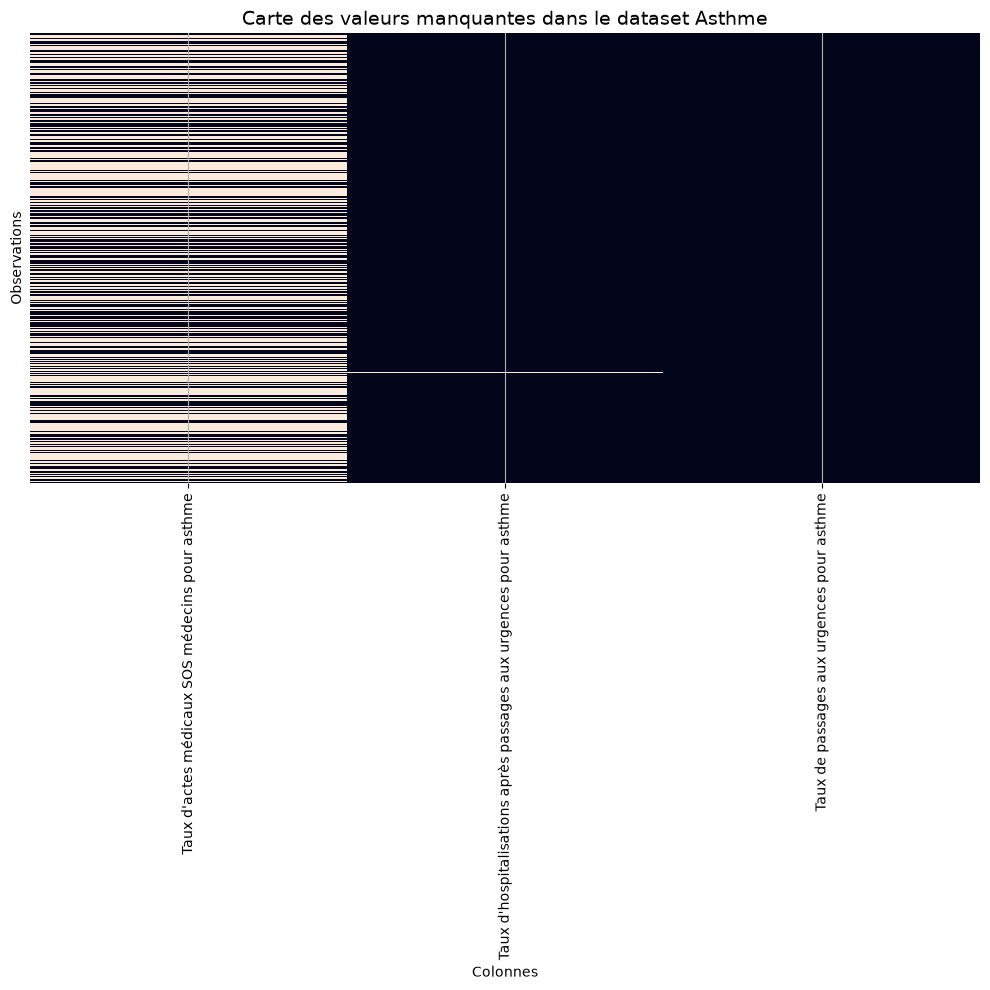

In [11]:
# Affiche le nombre de valeurs manquantes par colonne
missing_values = df_asthme.isna().sum()[lambda x: x > 0].sort_values(ascending=False)      #[lambda x: x > 0] → garde uniquement les colonnes qui ont au moins une valeur manquante.


# Visualisation: Heatmap des valeurs manquantes
plt.figure(figsize=(10, 10))
sns.heatmap(df_asthme[missing_values.index].isna(), cbar=False, yticklabels=False)
plt.title("Carte des valeurs manquantes dans le dataset Asthme", fontsize=14)
plt.xlabel("Colonnes")
plt.ylabel("Observations")
plt.tight_layout()
plt.grid(True)
plt.show()




In [13]:
#afficher les colonnes entierement vides pour les 3 taux cibles
colonnes = ["Taux de passages aux urgences pour asthme", "Taux d'hospitalisations après passages aux urgences pour asthme", "Taux d'actes médicaux SOS médecins pour asthme"]

display(df_asthme[df_asthme[colonnes].isna().all(axis=1)])

,Semaine,1er jour de la semaine,Département,Région,Classe d'âge,Taux de passages aux urgences pour asthme,Taux d'hospitalisations après passages aux urgences pour asthme,Taux d'actes médicaux SOS médecins pour asthme,Département Code,Région Code
96998,2022-S08,2022-02-21,Martinique,Martinique,00-14 ans,NaN,NaN,NaN,972,2
96999,2022-S08,2022-02-21,Martinique,Martinique,65 ans ou plus,NaN,NaN,NaN,972,2
97246,2022-S08,2022-02-21,Martinique,Martinique,15-64 ans,NaN,NaN,NaN,972,2
97247,2022-S08,2022-02-21,Martinique,Martinique,Tous âges,NaN,NaN,NaN,972,2


In [ ]:
#Valeurs uniques par colonnes
colonnes = df_asthme.columns.tolist()
df_asthme[colonnes].nunique()

Semaine                                                              300
1er jour de la semaine                                               300
Département                                                          101
Région                                                                18
Classe d'âge                                                           4
Taux de passages aux urgences pour asthme                          42404
Taux d'hospitalisations après passages aux urgences pour asthme    13953
Taux d'actes médicaux SOS médecins pour asthme                     17790
Département Code                                                     101
Région Code                                                           18
dtype: int64

In [ ]:
#quelles sont les valeurs uniques dans la colonne "Classe d'âge"
df_asthme["Classe d'âge"].unique()

<StringArray>
['65 ans ou plus', '15-64 ans', '00-14 ans', 'Tous âges']
Length: 4, dtype: str

In [ ]:
#Statistiques descriptives pour la colonne "Taux de passages aux urgences pour asthme"
df_asthme["Taux de passages aux urgences pour asthme"].describe()

count    120700.000000
mean       1028.908238
std        1335.736749
min           0.000000
25%         256.410256
50%         578.034682
75%        1230.650572
max       28070.175439
Name: Taux de passages aux urgences pour asthme, dtype: float64

In [ ]:
#Statistiques descriptives pour la colonne "Taux d'hospitalisations après passages aux urgences pour asthme"
df_asthme["Taux d'hospitalisations après passages aux urgences pour asthme"].describe()

count    120116.000000
mean       2086.462613
std        3897.271757
min           0.000000
25%           0.000000
50%         628.930818
75%        1837.672282
max      100000.000000
Name: Taux d'hospitalisations après passages aux urgences pour asthme, dtype: float64

In [ ]:
#Statistiques descriptives pour la colonne "Taux d'actes médicaux SOS médecins pour asthme" 
df_asthme["Taux d'actes médicaux SOS médecins pour asthme"].describe()

count    54678.000000
mean      1310.250227
std       1205.695517
min          0.000000
25%        531.914894
50%       1033.986356
75%       1756.920767
max      18181.818182
Name: Taux d'actes médicaux SOS médecins pour asthme, dtype: float64

In [ ]:
#Valeurs manquantes par département pour la colonne "Taux d'actes médicaux SOS médecins pour asthme"
manquant1 = df_asthme["Taux d'actes médicaux SOS médecins pour asthme"].isna()

taux_manquants = (
    manquant1.groupby(df_asthme["Département Code"])
    .mean()*100
)

taux_manquants.sort_values(ascending=False)

Département Code
01    100.0
03    100.0
04    100.0
05    100.0
07    100.0
      ...  
80      0.0
73      0.0
91      0.0
87      0.0
89      0.0
Name: Taux d'actes médicaux SOS médecins pour asthme, Length: 101, dtype: float64

In [ ]:
#Valeurs manquantes par département pour la colonne "Taux d'hospitalisations après passages aux urgences pour asthme"
manquant2 = df_asthme["Taux d'hospitalisations après passages aux urgences pour asthme"].isna()

taux_manquants = (
    manquant2.groupby(df_asthme["Département Code"])
    .mean()*100
)

taux_manquants.sort_values(ascending=False)

Département Code
972    41.666667
55     34.333333
48      5.500000
23      4.500000
43      1.083333
         ...    
94      0.000000
971     0.000000
95      0.000000
973     0.000000
974     0.000000
Name: Taux d'hospitalisations après passages aux urgences pour asthme, Length: 101, dtype: float64

In [ ]:
#Valeurs manquantes par département pour la colonne "Taux de passages aux urgences pour asthme"
manquant3 = df_asthme["Taux de passages aux urgences pour asthme"].isna()

taux_manquants = (
    manquant3.groupby(df_asthme["Département Code"])
    .mean()*100
)

taux_manquants.sort_values(ascending=False)

Département Code
972    41.666667
02      0.000000
03      0.000000
04      0.000000
01      0.000000
         ...    
94      0.000000
971     0.000000
973     0.000000
974     0.000000
976     0.000000
Name: Taux de passages aux urgences pour asthme, Length: 101, dtype: float64

Verification la coherence  des colonnes redondantes

In [ ]:
#comparer si "Semaine" correspond à "1er jour de la semaine" pour chaque ligne :
#0 je fais un copie pour pas modifier l'originale df_asthme
df_asthme2 = df_asthme.copy()
# 1. Tranformation de la date en numero de semaine
# nettoyage
df_asthme2.columns = (
    df_asthme2.columns
    .str.replace(" ", "_")
    .str.strip()
)

df_asthme2.info()

#2. Transformation de la colonne "1er_jour_de_la_semaine" en datetime (date impossible devient NaT, valeur manquant)
col_date = "1er_jour_de_la_semaine"

dates = pd.to_datetime(
    df_asthme2[col_date], format="%Y-%m-%d", errors="coerce"
)

#extraire l'année et la semaine de la date
iso = dates.dt.isocalendar()

#reconstruction de la meme format que la colonne "Semaine" : "YYYY-SWW"
semaine_calculee = (
    iso["year"].astype("string")
    + "-S"
    + iso["week"].astype("string").str.zfill(2)


)


semaine_source = df_asthme["Semaine"]

#Verification
valide = (
    semaine_source.notna()                      #La semaine est renseignée
    & dates.notna()                             #La date est present et pu etre convertie  
    & semaine_source.eq(semaine_calculee)       #La semaine correspond à la date
    & dates.dt.dayofweek.eq(0)                  #La date est un lundi (0 = lundi, 1 = mardi, ..., 6 = dimanche)
).fillna(False)

print(f"{valide.sum()} lignes cohérentes sur {len(df_asthme2)}")




<class 'pandas.DataFrame'>
RangeIndex: 121200 entries, 0 to 121199
Data columns (total 10 columns):
 #   Column                                                           Non-Null Count   Dtype  
---  ------                                                           --------------   -----  
 0   Semaine                                                          121200 non-null  str    
 1   1er_jour_de_la_semaine                                           121200 non-null  str    
 2   Département                                                      121200 non-null  str    
 3   Région                                                           121200 non-null  str    
 4   Classe_d'âge                                                     121200 non-null  str    
 5   Taux_de_passages_aux_urgences_pour_asthme                        120700 non-null  float64
 6   Taux_d'hospitalisations_après_passages_aux_urgences_pour_asthme  120116 non-null  float64
 7   Taux_d'actes_médicaux_SOS_médecins_pour_

In [ ]:

#comparer si Region correspond à Région Code pour chaque ligne 
    #Est-ce que chaque nom de région possède un seul code ?
    #Est-ce que chaque code possède un seul nom de région ?

#creation tableau de travail
paires = df_asthme2[["Région", "Région_Code"]].copy()

#pour chaque colonne on transforme en texte, retire les espaces et remplace les valeurs vides par NaN si applicable
for col in ["Région", "Région_Code"]:
    paires[col] = (
        paires[col].astype("string").str.strip().replace("", pd.NA)
    )


#Garder les associations distinctes et complètes et on retire les repetitions des lignes entieres pour ne garder que les paires uniques
# Garder une seule fois chaque association région / code
paires = df_asthme[
    ["Région", "Région_Code"]
].drop_duplicates()

# Chercher les noms associés à plusieurs codes
# ou les codes associés à plusieurs noms
conflits = paires[
    paires.duplicated("Région", keep=False)
    | paires.duplicated("Région_Code", keep=False)
]

display(conflits)



,Région,Région_Code


In [ ]:

#comparer si Département correspond à Département Code pour chaque ligne

    #Est-ce que chaque nom de département possède un seul code ?
    #Est-ce que chaque code possède un seul nom de departement ?

#creation tableau de travail
paires = df_asthme2[["Département", "Département_Code"]].copy()

#pour chaque colonne on transforme en texte, retire les espaces et remplace les valeurs vides par NaN si applicable
for col in ["Département", "Département_Code"]:
    paires[col] = (
        paires[col].astype("string").str.strip().replace("", pd.NA)
    )


#Garder les associations distinctes et complètes et on retire les repetitions des lignes entieres pour ne garder que les paires uniques
# Garder une seule fois chaque association département / code
paires = df_asthme[
    ["Département", "Département_Code"]
].drop_duplicates()

# Chercher les noms associés à plusieurs codes
# ou les codes associés à plusieurs noms
conflits = paires[
    paires.duplicated("Département", keep=False)
    | paires.duplicated("Département_Code", keep=False)
]

display(conflits)



,Département,Département_Code


Lignes avec une information manquante : 0
Paires impliquées dans une correspondance ambiguë : 0

Attention! Cela ne garantit pas que les codes sont officiellement corrects. Une mauvaise association répétée partout passerait ce contrôle. La vérification officielle nécessite un référentiel adapté à la période des données.